# 日付のあるテキストから急に増えた語を見つける（バースト検出）

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/mamorlis/nlpcookbook/blob/main/notebooks/11_topics_keywords/burst_detection.ipynb)

NLP クックブック 11-09 ／ トピックとキーワードの抽出

日付の付いたニュース記事の流れから、ある時期に急に増えた語（話題）と、その期間を見つけたい。

In [1]:
!pip install -q fugashi unidic-lite matplotlib-fontja

In [2]:
import io, tarfile, urllib.request
import pandas as pd

# livedoor ニュースコーパス (株式会社ロンウイット配布)。記事は CC BY-ND 2.1 JP (表示・改変禁止)
def load_livedoor():
    url = "https://www.rondhuit.com/download/ldcc-20140209.tar.gz"
    with urllib.request.urlopen(url) as r:
        tar = tarfile.open(fileobj=io.BytesIO(r.read()), mode="r:gz")
    rows = []
    for m in tar.getmembers():
        parts = m.name.split("/")
        if m.isfile() and len(parts) == 3 and parts[2] != "LICENSE.txt":
            lines = tar.extractfile(m).read().decode("utf-8").split("\n")
            rows.append({"label": parts[1], "date": lines[1], "title": lines[2], "text": "\n".join(lines[3:])})
    return pd.DataFrame(rows)

df = load_livedoor()
df["date"] = pd.to_datetime(df["date"].str[:10])
# カテゴリごとに収録の時期が違うので、毎月の記事がある「Sports Watch」だけを使う。
# 収録の最初と最後の月 (2010-02 は 12 件、2012-09 は 3 件) は記事が少ないので除く
df = df[(df.label == "sports-watch") & (df.date >= "2010-03-01") & (df.date < "2012-09-01")].reset_index(drop=True)
df["month"] = df["date"].dt.to_period("M")
print(len(df), "件")
print(df.groupby("month").size().to_string())

885 件
month
2010-03    21
2010-04    19
2010-05    26
2010-06    24
2010-07    20
2010-08    22
2010-09    23
2010-10    25
2010-11    25
2010-12    25
2011-01    25
2011-02    23
2011-03    22
2011-04    27
2011-05    26
2011-06    38
2011-07    35
2011-08    26
2011-09    30
2011-10    34
2011-11    34
2011-12    38
2012-01    47
2012-02    64
2012-03    53
2012-04    23
2012-05    24
2012-06    22
2012-07    33
2012-08    31
Freq: M


In [3]:
import re
from collections import Counter
from fugashi import Tagger

tagger = Tagger()

def clean(title, text):
    """時期によって書式が変わる定型部分 (見出しの【Sports Watch】、関連リンクの一覧) を除く"""
    title = re.sub(r"^【[^】]*】\s*", "", title)
    text = text.split("関連リンク")[0]
    return title + "\n" + "\n".join(l for l in text.split("\n") if not l.startswith(("・", "■", "【")))

def nouns(text):
    return {w.surface for w in tagger(text) if w.feature.pos1 == "名詞" and w.feature.pos2 in ("普通名詞", "固有名詞")
            and len(w.surface) > 1}

df["words"] = [nouns(clean(a, b)) for a, b in zip(df["title"], df["text"])]   # 1 記事に何回出ても 1 と数える (文書頻度)

months = pd.period_range(df["month"].min(), df["month"].max(), freq="M")
d = df.groupby("month").size().reindex(months, fill_value=0).to_numpy()          # 各月の記事数
total = Counter(w for ws in df["words"] for w in ws)
vocab = sorted(w for w, c in total.items() if c >= 10)                                # 全体で 10 記事以上に出る語
R = pd.DataFrame(0, index=vocab, columns=months)                                  # 語 × 月 の記事数
vs = set(vocab)
for m, ws in zip(df["month"], df["words"]):
    for w in ws & vs:
        R.loc[w, m] += 1
print(R.shape)

(1155, 30)


In [4]:
# 方法 1: 単純な頻度の比。その月の出現率を、直前 3 か月の出現率と比べる
def ratio_table(R, d, prev=3, min_count=5):
    rows = []
    for t in range(prev, len(d)):
        cur = (R.iloc[:, t] + 0.5) / (d[t] + 1)
        base = (R.iloc[:, t - prev:t].sum(axis=1) + 0.5) / (d[t - prev:t].sum() + 1)
        for w in R.index[R.iloc[:, t] >= min_count]:
            rows.append({"word": w, "month": str(R.columns[t]), "count": R.loc[w, R.columns[t]], "ratio": cur[w] / base[w]})
    return pd.DataFrame(rows).sort_values("ratio", ascending=False, kind="stable").reset_index(drop=True)

ratio = ratio_table(R, d)
ratio.head(15)

,word,month,count,ratio
0,川澄,2011-07,9,48.555556
1,穂希,2011-07,9,48.555556
2,震災,2011-03,6,41.826087
3,セルジオ,2010-06,7,40.200000
4,越後,2010-06,7,40.200000
5,奈穂美,2011-07,7,38.333333
6,中国,2012-08,6,32.500000
7,みの,2012-03,5,30.555556
8,もんた,2012-03,5,30.555556
9,起用,2012-03,5,30.555556


In [5]:
import numpy as np
from scipy.stats import binom

# 方法 2: Kleinberg (2002) のバースト検出 (バッチのデータ用の 2 状態モデル)。
# 各月の記事数 d_t のうち語を含む記事数 r_t が、通常状態 (出現率 p0) と
# バースト状態 (出現率 p1 = s * p0) のどちらで説明しやすいかを、状態を上げるコスト gamma * log(n) と合わせて
# ビタビアルゴリズムで決める
def kleinberg_bursts(r, d, s=2.0, gamma=1.0):
    r, d = np.asarray(r), np.asarray(d)
    n = len(r)
    p0 = r.sum() / d.sum()
    p1 = min(s * p0, 0.9999)
    cost = -np.stack([binom.logpmf(r, d, p0), binom.logpmf(r, d, p1)])   # 2 × n
    up = gamma * np.log(n)
    C = np.array([cost[0, 0], cost[1, 0] + up])
    back = np.zeros((n, 2), dtype=int)
    for t in range(1, n):
        to0 = [C[0], C[1]]                # 状態を下げるコストは 0
        to1 = [C[0] + up, C[1]]
        back[t] = [np.argmin(to0), np.argmin(to1)]
        C = np.array([min(to0) + cost[0, t], min(to1) + cost[1, t]])
    q = np.zeros(n, dtype=int)
    q[-1] = C.argmin()
    for t in range(n - 1, 0, -1):
        q[t - 1] = back[t, q[t]]
    # 連続するバースト状態を 1 つのバーストとし、強さ = 区間内のコストの差の合計
    out, gain = [], cost[0] - cost[1]
    for t in range(n):
        if q[t] == 1 and (t == 0 or q[t - 1] == 0):
            start = t
        if q[t] == 1 and (t == n - 1 or q[t + 1] == 0):
            out.append((start, t, gain[start:t + 1].sum()))
    return out

rows = [{"word": w, "begin": str(months[b]), "end": str(months[e]), "b": b, "e": e, "weight": wt}
        for w in R.index for b, e, wt in kleinberg_bursts(R.loc[w].to_numpy(), d)]
bursts = pd.DataFrame(rows).sort_values("weight", ascending=False, kind="stable").reset_index(drop=True)
print(len(bursts), "個のバースト")
bursts.head(15)[["word", "begin", "end", "weight"]]

313 個のバースト


,word,begin,end,weight
0,五輪,2012-04,2012-08,33.898004
1,ロンドン,2012-03,2012-08,32.912908
2,メダル,2012-07,2012-08,22.820339
3,ジャパン,2011-07,2011-09,19.243746
4,なでしこ,2011-07,2011-09,19.067244
5,ネット,2011-10,2012-02,19.065318
6,アサヒ,2010-09,2011-10,15.421714
7,獲得,2012-04,2012-08,14.930121
8,週刊,2010-09,2011-09,14.562999
9,同誌,2010-09,2011-10,14.518730


In [6]:
# 2 つの方法の比較: 頻度の比の上位 15 件が、Kleinberg では何位のバーストの期間に入っているか
def kleinberg_rank(w, m):
    t = months.get_loc(pd.Period(m, "M"))
    hit = bursts[(bursts.word == w) & (bursts.b <= t) & (bursts.e >= t)]
    return hit.index[0] + 1 if len(hit) else None

cmp = ratio.head(15).copy()
cmp["kleinberg_rank"] = pd.array([kleinberg_rank(w, m) for w, m in zip(cmp.word, cmp.month)], dtype="Int64")
print("比が 3 倍以上の (語, 月):", (ratio.ratio >= 3).sum(), "件 / Kleinberg のバースト:", len(bursts), "個")
cmp

比が 3 倍以上の (語, 月): 270 件 / Kleinberg のバースト: 313 個


,word,month,count,ratio,kleinberg_rank
0,川澄,2011-07,9,48.555556,52
1,穂希,2011-07,9,48.555556,25
2,震災,2011-03,6,41.826087,19
3,セルジオ,2010-06,7,40.200000,165
4,越後,2010-06,7,40.200000,166
5,奈穂美,2011-07,7,38.333333,90
6,中国,2012-08,6,32.500000,<NA>
7,みの,2012-03,5,30.555556,155
8,もんた,2012-03,5,30.555556,156
9,起用,2012-03,5,30.555556,<NA>


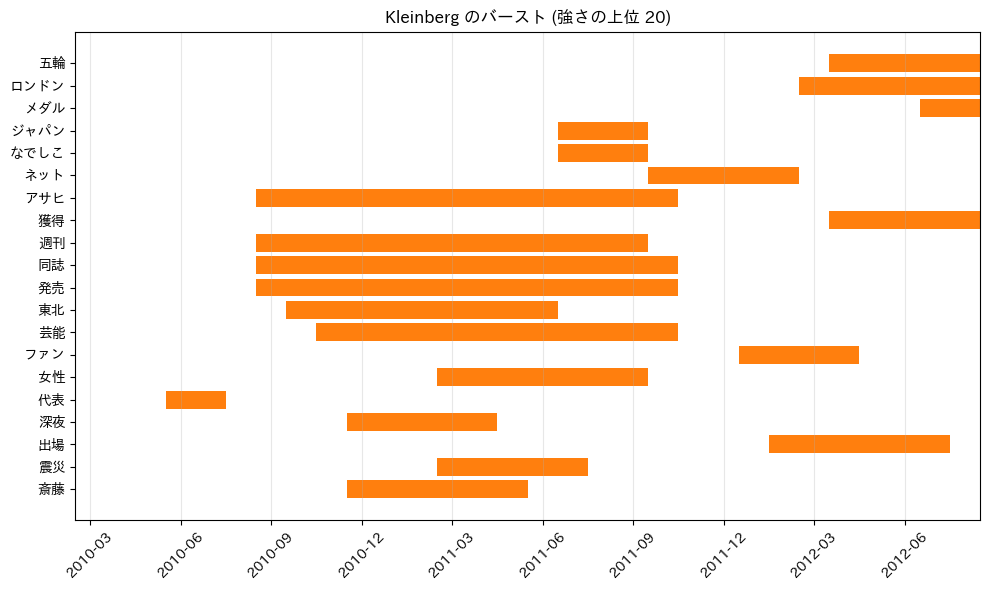

In [7]:
import matplotlib.pyplot as plt
import matplotlib_fontja

# 強いバースト上位 20 個の期間を横棒で示す
top = bursts.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(range(len(top)), top["e"] - top["b"] + 1, left=top["b"] - 0.5, color="tab:orange")   # 月 i を i-0.5〜i+0.5 に描く
ax.set_yticks(range(len(top)), top["word"])
ticks = list(range(0, len(months), 3))
ax.set_xticks(ticks, [str(months[i]) for i in ticks], rotation=45)
ax.set_xlim(-0.5, len(months) - 0.5); ax.grid(axis="x", alpha=0.3)
ax.set_title("Kleinberg のバースト (強さの上位 20)")
plt.tight_layout(); plt.show()

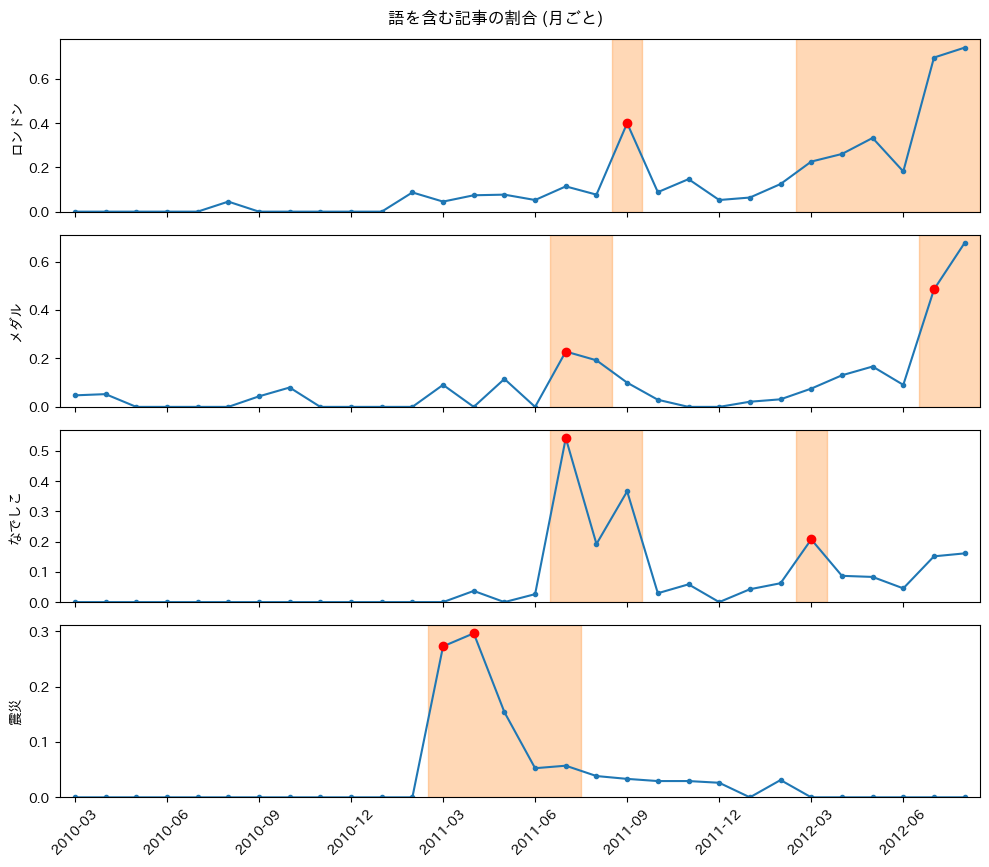

In [8]:
# 語ごとの出現率の推移。橙の帯が Kleinberg のバースト期間、赤い点が頻度の比で 3 倍以上になった月
words = ["ロンドン", "メダル", "なでしこ", "震災"]
fig, axes = plt.subplots(len(words), 1, figsize=(10, 2.2 * len(words)), sharex=True)
for ax, w in zip(axes, words):
    ax.plot(range(len(months)), R.loc[w] / d, marker=".", color="tab:blue")
    for _, b in bursts[bursts.word == w].iterrows():
        ax.axvspan(b["b"] - 0.5, b["e"] + 0.5, color="tab:orange", alpha=0.3)
    hit = ratio[(ratio.word == w) & (ratio.ratio >= 3)]
    idx = [months.get_loc(pd.Period(m, "M")) for m in hit["month"]]
    ax.scatter(idx, (R.loc[w] / d).iloc[idx], color="red", zorder=3)
    ax.set_ylabel(w); ax.set_ylim(bottom=0)
axes[-1].set_xticks(ticks, [str(months[i]) for i in ticks], rotation=45)
axes[-1].set_xlim(-0.5, len(months) - 0.5)
fig.suptitle("語を含む記事の割合 (月ごと)")
plt.tight_layout(); plt.show()

- 頻度の比は計算が簡単だが、直前にほとんど出ていない語が数記事出ただけで比が大きくなる。この出力でも比の上位 15 件は 5〜9 記事の語で、そのうち 6 件は Kleinberg のバーストの期間に入っていない。逆に直前の数か月も多い月は比が大きくならないので、「ロンドン」のように 2012 年に数か月かけて増えた語は、2012 年には 3 倍を超えない。
- Kleinberg のバースト検出は KDD 2002 で発表された（雑誌版は Data Mining and Knowledge Discovery, 2003）。ここでは論文のバッチ用のモデルで、出現率 p0 = R/D の状態と p1 = s·p0 の状態のどちらにいるかを、二項分布の負の対数尤度と状態を上げるコスト γ ln n の合計が最小になるように決める。頻度の比と違って始まりと終わりの期間が得られ、記事数の少ない月のばらつきを二項分布で考慮した強さ（p1 で説明したときのコストの減りの合計）で順位を付けられる。
- `s` を大きくすると大きく増えた語だけがバーストになる。`gamma` を大きくするとバーストに入りにくくなり、弱い増加や短い増加はバーストになりにくい。月の記事数が 19〜64 件と少ないので月単位にまとめたが、記事の多いデータなら週や日の単位にできる。
- PyPI の `burst_detection` (0.1.3) は NumPy から削除された `np.float` を使っていて、検証に使った Colab のイメージ (NumPy 2.4) ではエラーになり、分類も "Free for non-commercial use" なので、ここでは 2 状態のビタビを自分で書いた。メールのように 1 件ずつ届く時刻の列には、論文の前半の連続時間のモデル（R の `bursts` パッケージなど）を使う。
- livedoor ニュースコーパスの記事は CC BY-ND 2.1 JP（表示・改変禁止）。カテゴリごとに収録の時期が違う（例: topic-news は 2011 年 10 月から、smax は 2012 年 4 月から）ので、収録の始まりがバーストに見えないよう Sports Watch だけを使い、時期によって変わる定型文（見出しの【Sports Watch】、関連リンクの一覧）も除いた。それでも上位の「ネット」「アサヒ」「週刊」「同誌」などは話題より書き方の変化を拾った可能性があり（中身は確かめていない）、検出結果は元の記事を読んで確かめる。
- 名詞を 1 語ずつ数えているので、「川澄」「穂希」「奈穂美」のように人名が分かれて別々に出る。名詞の連続をつないで数える（この章の「文書からキーワードを抽出する（埋め込みによる KeyBERT 方式）」の `candidates`）と読みやすくなる。
- 語の代わりに、この章の「LDA で文書集合のトピックを見つける」や「文埋め込みとクラスタリングでトピックを作る（BERTopic 方式）」で各文書に割り当てたトピックを数えて r_t にすれば、同じ関数で話題のバーストを検出できる。2 つの期間だけを比べるなら、コーパスの統計と可視化の章の「2 つのコーパスを比べて特徴語を見つける（対数尤度比）」も使える。